In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

# =====================================================
# EDIT OUTPUT DIRECTORY
# =====================================================

OUTPUT_DIR = Path(
    "/Users/amitgupta/Desktop/NUS/BN5212/"
    "Final Group Project/Post mid-term/Model_Results"
)

CM_DIR = OUTPUT_DIR / "confusion_matrices"
RESULTS_CSV = OUTPUT_DIR / "all_experiment_results.csv"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CM_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# EXPERIMENT SETTINGS
# =====================================================

TARGET = "icu_transfer"
SEED = 42
VAL_SIZE = 0.20

# Options: "max_f1" or "recall_target"
THRESHOLD_STRATEGY = "max_f1"
TARGET_RECALL = 0.60

# =====================================================
# PREPROCESSING
# =====================================================

def make_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True
        )),
        ("scaler", StandardScaler())
    ])

# =====================================================
# MODELS
# =====================================================

def make_models():

    svm = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", LinearSVC(
            C=0.1,
            class_weight="balanced",
            dual=False,
            max_iter=10000,
            tol=1e-4,
            random_state=SEED
        ))
    ])

    mlp = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.01,
            batch_size=256,
            learning_rate_init=0.001,
            max_iter=50,
            early_stopping=False,
            random_state=SEED
        ))
    ])

    return {"SVM": svm, "MLP": mlp}

# =====================================================
# GET MODEL SCORES
# =====================================================

def get_scores(model, X, model_name):

    if model_name == "SVM":
        return model.decision_function(X)

    return model.predict_proba(X)[:, 1]

# =====================================================
# SELECT THRESHOLD ON VALIDATION DATA
# =====================================================

def select_threshold(y_true, scores):

    precision, recall, thresholds = precision_recall_curve(
        y_true, scores
    )

    p = precision[:-1]
    r = recall[:-1]

    if THRESHOLD_STRATEGY == "max_f1":

        f1_values = 2 * p * r / np.maximum(p + r, 1e-12)
        idx = np.argmax(f1_values)

    elif THRESHOLD_STRATEGY == "recall_target":

        valid = np.where(r >= TARGET_RECALL)[0]

        if len(valid) == 0:
            raise ValueError("Recall target not achievable.")

        idx = valid[np.argmax(p[valid])]

    else:
        raise ValueError("Unknown threshold strategy")

    return float(thresholds[idx])

# =====================================================
# EVALUATION METRICS
# =====================================================

def calculate_metrics(
    dataset_name,
    model_name,
    y_true,
    scores,
    threshold,
    n_features,
    n_train,
    n_val,
    train_time
):

    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0
    npv = tn / (tn + fn) if (tn + fn) else 0

    result = {
        "Dataset": dataset_name,
        "Model": model_name,
        "Features": n_features,
        "Train_Rows": n_train,
        "Validation_Rows": n_val,
        "Test_Rows": len(y_true),
        "Test_Positive_Rate": float(np.mean(y_true)),
        "Threshold_Strategy": THRESHOLD_STRATEGY,
        "Target_Recall": (
            TARGET_RECALL
            if THRESHOLD_STRATEGY == "recall_target"
            else np.nan
        ),
        "Threshold": threshold,

        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Specificity": specificity,
        "NPV": npv,
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC_AP": average_precision_score(
            y_true, scores
        ),
        "Cohen_Kappa": cohen_kappa_score(
            y_true, predictions
        ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),

        "Training_Time_Seconds": train_time
    }

    return result, predictions

# =====================================================
# SAVE CONFUSION MATRIX
# =====================================================

def save_cm(y_true, predictions, dataset_name, model_name):

    cm = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No ICU", "ICU Transfer"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{dataset_name} - {model_name}")
    fig.tight_layout()

    filename = f"{dataset_name}_{model_name}_CM.png"
    fig.savefig(CM_DIR / filename, dpi=300)
    plt.close(fig)

# =====================================================
# SAVE RESULTS TO ONE CSV
# =====================================================

def save_results(rows):

    new_results = pd.DataFrame(rows)

    if RESULTS_CSV.exists():
        old_results = pd.read_csv(RESULTS_CSV)

        # Replace previous results for the same
        # dataset/model/threshold configuration.
        keys = ["Dataset", "Model", "Threshold_Strategy"]

        if all(k in old_results.columns for k in keys):
            new_keys = pd.MultiIndex.from_frame(
                new_results[keys]
            )
            old_keys = pd.MultiIndex.from_frame(
                old_results[keys]
            )
            old_results = old_results[
                ~old_keys.isin(new_keys)
            ]

        combined = pd.concat(
            [old_results, new_results],
            ignore_index=True
        )
    else:
        combined = new_results

    combined.to_csv(RESULTS_CSV, index=False)

    print("Results saved to:", RESULTS_CSV)

# =====================================================
# RUN BOTH MODELS ON ONE DATASET
# =====================================================

def run_models(dataset_name, train_data, test_data,
               validation_subject_ids):

    print("\n" + "=" * 65)
    print("DATASET:", dataset_name)
    print("=" * 65)

    assert train_data["subject_id"].notna().all()
    assert test_data["subject_id"].notna().all()

    assert set(train_data["subject_id"]).isdisjoint(
        set(test_data["subject_id"])
    ), "Patient overlap between train and test!"

    assert train_data["hadm_id"].is_unique
    assert test_data["hadm_id"].is_unique

    exclude = {
        "subject_id", "hadm_id",
        "dataset_split", TARGET
    }

    features = [
        c for c in train_data.columns
        if c not in exclude
    ]

    assert set(features) == (
        set(test_data.columns) - exclude
    ), "Training/testing feature mismatch!"

    # Prevent silent conversion of non-numeric columns
    for c in features:
        if not pd.api.types.is_numeric_dtype(train_data[c]):
            raise ValueError(f"Non-numeric training feature: {c}")
        if not pd.api.types.is_numeric_dtype(test_data[c]):
            raise ValueError(f"Non-numeric testing feature: {c}")

    X = train_data[features]
    y = train_data[TARGET].astype(int)

    X_test = test_data[features]
    y_test = test_data[TARGET].astype(int)

    assert set(y.unique()) == {0, 1}
    assert set(y_test.unique()) == {0, 1}

    # Same validation patients for both feature sets
    val_mask = train_data["subject_id"].isin(
        validation_subject_ids
    )

    X_train = X.loc[~val_mask]
    X_val = X.loc[val_mask]

    y_train = y.loc[~val_mask]
    y_val = y.loc[val_mask]

    assert len(X_train) > 0 and len(X_val) > 0
    assert y_train.nunique() == 2 and y_val.nunique() == 2

    print("Number of features:", len(features))
    print("Training rows:", len(X_train))
    print("Validation rows:", len(X_val))
    print("Test rows:", len(X_test))

    all_results = []

    for model_name, model in make_models().items():

        print(f"\nTraining {model_name}...")

        # Stage 1: Fit on training subset
        # and select threshold on validation.
        model.fit(X_train, y_train)

        val_scores = get_scores(
            model, X_val, model_name
        )

        threshold = select_threshold(
            y_val, val_scores
        )

        print("Validation threshold:", threshold)

        # Stage 2: Refit using all original training data.
        # The test set remains untouched during fitting.
        final_model = clone(model)

        start = time.perf_counter()
        final_model.fit(X, y)
        train_time = time.perf_counter() - start

        scores = get_scores(
            final_model, X_test, model_name
        )

        result, predictions = calculate_metrics(
            dataset_name=dataset_name,
            model_name=model_name,
            y_true=y_test,
            scores=scores,
            threshold=threshold,
            n_features=len(features),
            n_train=len(X),
            n_val=len(X_val),
            train_time=train_time
        )

        save_cm(
            y_test,
            predictions,
            dataset_name,
            model_name
        )

        all_results.append(result)

        print(
            f"Accuracy={result['Accuracy']:.4f} | "
            f"Precision={result['Precision']:.4f} | "
            f"Recall={result['Recall']:.4f} | "
            f"F1={result['F1']:.4f} | "
            f"AP={result['PR_AUC_AP']:.4f}"
        )

    save_results(all_results)

    return pd.DataFrame(all_results)

In [2]:
# =====================================================
# DATASET 75
# =====================================================

DATASET_75_PATH = Path(
    '/Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/75_Feature_Dataset.xlsx'
)

df_75 = pd.read_excel(
    DATASET_75_PATH,
    sheet_name="Final_75_Features"
)

train_75 = df_75[
    df_75["dataset_split"] == "train"
].copy()

test_75 = df_75[
    df_75["dataset_split"] == "test"
].copy()

assert len(train_75) + len(test_75) == len(df_75)
assert len(train_75) == 66118
assert len(test_75) == 22223

# Create one fixed patient-disjoint validation split.
# Reuse these same patients for the 200-feature experiment.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_75,
        train_75[TARGET],
        groups=train_75["subject_id"]
    )
)

validation_subject_ids = set(
    train_75.iloc[val_idx]["subject_id"]
)

# Train and evaluate
results_75 = run_models(
    dataset_name="75_Features",
    train_data=train_75,
    test_data=test_75,
    validation_subject_ids=validation_subject_ids
)

display(results_75.round(4))

KeyboardInterrupt: 

In [ ]:
# 17/10/26

# =====================================================
# DATASET 200
# =====================================================

DATASET_200_PATH = Path(
    '/Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/200_Feature_Dataset.xlsx'
)

# Reuse already-loaded DataFrames if available
if "train_df" not in globals():
    train_df = pd.read_excel(
        DATASET_200_PATH,
        sheet_name="Training Data"
    )

if "test_df" not in globals():
    test_df = pd.read_excel(
        DATASET_200_PATH,
        sheet_name="Testing Data"
    )

# Verify same admission population and split
assert set(train_df["hadm_id"]) == set(train_75["hadm_id"])
assert set(test_df["hadm_id"]) == set(test_75["hadm_id"])

# Verify identical target labels
for a, b in [
    (train_df, train_75),
    (test_df, test_75)
]:
    check = a[["hadm_id", TARGET]].merge(
        b[["hadm_id", TARGET]],
        on="hadm_id",
        suffixes=("_200", "_75"),
        validate="one_to_one"
    )

    assert (
        check[f"{TARGET}_200"] ==
        check[f"{TARGET}_75"]
    ).all(), "Target labels differ!"

# Run the models
results_200 = run_models(
    dataset_name="200_Features",
    train_data=train_df,
    test_data=test_df,
    validation_subject_ids=validation_subject_ids
)

display(results_200.round(4))


DATASET: 200_Features
Number of features: 200
Training rows: 52613
Validation rows: 13505
Test rows: 22223

Training SVM...


In [ ]:
all_results = pd.read_csv(RESULTS_CSV)

columns_to_show = [
    "Dataset",
    "Model",
    "Features",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced_Accuracy",
    "Specificity",
    "ROC_AUC",
    "PR_AUC_AP",
    "Cohen_Kappa",
    "Training_Time_Seconds"
]

display(
    all_results[columns_to_show]
    .sort_values("PR_AUC_AP", ascending=False)
    .round(4)
)

,Dataset,Model,Features,Accuracy,Precision,Recall,F1,Balanced_Accuracy,Specificity,ROC_AUC,PR_AUC_AP,Cohen_Kappa,Training_Time_Seconds
2,200_Features,SVM,200,0.9334,0.1647,0.2545,0.2000,0.6054,0.9564,0.7444,0.1176,0.1669,122.6726
0,75_Features,SVM,75,0.9140,0.1328,0.2944,0.1830,0.6147,0.9350,0.7456,0.1108,0.1444,18.4076
1,75_Features,MLP,75,0.9349,0.1188,0.1541,0.1341,0.5577,0.9613,0.6675,0.0870,0.1009,10.2879
3,200_Features,MLP,200,0.9163,0.1058,0.2091,0.1405,0.5747,0.9403,0.6508,0.0822,0.1015,19.8372


In [ ]:
classifier = final_model.named_steps["classifier"]

print("Model:", type(classifier).__name__)
print("Iterations/epochs:", classifier.n_iter_)

if hasattr(classifier, "loss_curve_"):
    print("Final loss:", classifier.loss_curve_[-1])

preprocessed_features = final_model.named_steps[
    "preprocess"
].transform(X.iloc[:2])

print("Actual input dimensions:", preprocessed_features.shape[1])

NameError: name 'final_model' is not defined

In [ ]:

# finding actual training variables
for name, value in globals().copy().items():
    if (
        any(term in name.lower() for term in [
            "train", "test", "val", "split",
            "dataset", "feature", "group", "subject"
        ])
        and not name.startswith("_")
    ):
        if hasattr(value, "shape"):
            print(f"{name:35s} {str(value.shape):20s}")
        elif isinstance(value, (dict, list, tuple)):
            print(f"{name:35s} {type(value).__name__}: {len(value)} items")

train_75                            (66118, 79)         
test_75                             (22223, 79)         
train_idx                           (52613,)            
val_idx                             (13505,)            
train_df                            (66118, 203)        
test_df                             (22223, 203)        


In [ ]:
# running 5 random hyperparameter tuning experiments - to see what yields what and deciding which parameters should be tuned after that

import numpy as np
import pandas as pd
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from scipy.stats import loguniform

RANDOM_STATE = 42

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

datasets = {
    "75_Features": (X_train_75, y_train_75),
    "200_Features": (X_train_200, y_train_200)
}

models = {
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            max_iter=10000,
            random_state=RANDOM_STATE
        ))
    ]),

    "MLP": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(
            max_iter=200,
            early_stopping=True,
            random_state=RANDOM_STATE
        ))
    ])
}

param_distributions = {
    "SVM": {
        "classifier__C": loguniform(0.001, 100),
        "classifier__class_weight": [
            None, "balanced",
            {0: 1, 1: 5},
            {0: 1, 1: 10},
            {0: 1, 1: 20}
        ]
    },

    "MLP": {
        "classifier__hidden_layer_sizes": [
            (32,), (64,), (128,),
            (64, 32), (128, 64)
        ],
        "classifier__alpha": loguniform(1e-5, 1e-1),
        "classifier__learning_rate_init": loguniform(1e-4, 3e-3),
        "classifier__batch_size": [128, 256, 512]
    }
}

results = []
best_models = {}

for dataset_name, (X, y) in datasets.items():

    for model_name, model in models.items():

        print(f"\nTuning {dataset_name} - {model_name}")

        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_distributions[model_name],
            n_iter=5,  # Pilot; increase to 20 later
            scoring="average_precision",
            cv=cv,
            n_jobs=1,
            random_state=RANDOM_STATE,
            refit=True,
            verbose=1,
            error_score="raise"
        )

        start = time.perf_counter()
        search.fit(X, y)
        elapsed = time.perf_counter() - start

        best_models[(dataset_name, model_name)] = (
            search.best_estimator_
        )

        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Best_CV_AP": search.best_score_,
            "Best_Params": search.best_params_,
            "Search_Time_Seconds": elapsed
        })

results_df = pd.DataFrame(results)
display(results_df)

NameError: name 'X_train_75' is not defined

In [ ]:
import pandas as pd

DATASET_75_PATH = (
    "/Users/amitgupta/Desktop/NUS/BN5212/"
    "Final Group Project/Post mid-term/"
    "75_Feature_Dataset.xlsx"
)

df_75 = pd.read_excel(
    DATASET_75_PATH,
    sheet_name="Final_75_Features"
)

train_75 = df_75[
    df_75["dataset_split"] == "train"
].copy()

print("Training dataset loaded:", train_75.shape)

Training dataset loaded: (66118, 79)


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_75,
        train_75["icu_transfer"],
        groups=train_75["subject_id"]
    )
)

validation_subject_ids = set(
    train_75.iloc[val_idx]["subject_id"]
)

print("Validation patients:", len(validation_subject_ids))

Validation patients: 5782


In [ ]:
# hyper parameter tuning

from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

import itertools
import time
import warnings

TUNING_CSV = OUTPUT_DIR / "hyperparameter_tuning.csv"

def prepare_tuning_data(data, feature_names=None):

    excluded = {
        "subject_id", "hadm_id",
        "dataset_split", "icu_transfer"
    }

    features = (
        feature_names if feature_names is not None
        else [c for c in data.columns if c not in excluded]
    )

    val_mask = data["subject_id"].isin(validation_subject_ids)

    X_train = data.loc[~val_mask, features]
    X_val = data.loc[val_mask, features]

    y_train = data.loc[~val_mask, TARGET].astype(int)
    y_val = data.loc[val_mask, TARGET].astype(int)

    assert y_train.nunique() == 2
    assert y_val.nunique() == 2
    assert not set(data.loc[~val_mask, "subject_id"]) & set(
        data.loc[val_mask, "subject_id"]
    )

    return X_train, X_val, y_train, y_val

In [ ]:
def get_tuning_candidates():

    candidates = []

    # Linear SVM: 6 configurations
    for C, weight in itertools.product(
        [0.01, 0.1, 1.0],
        [None, "balanced"]
    ):
        candidates.append((
            "LinearSVM",
            {"C": C, "class_weight": weight},
            Pipeline([
                ("preprocess", make_preprocessor()),
                ("classifier", LinearSVC(
                    C=C,
                    class_weight=weight,
                    dual=False,
                    max_iter=3000,
                    tol=1e-3,
                    random_state=42
                ))
            ])
        ))

    # Approximate RBF SVM: 4 configurations
    for gamma, C in itertools.product(
        [0.001, 0.01],
        [0.1, 1.0]
    ):
        candidates.append((
            "ApproxRBF_SVM",
            {"gamma": gamma, "C": C, "components": 300},
            Pipeline([
                ("preprocess", make_preprocessor()),
                ("rbf", RBFSampler(
                    gamma=gamma,
                    n_components=300,
                    random_state=42
                )),
                ("classifier", LinearSVC(
                    C=C,
                    class_weight="balanced",
                    dual=False,
                    max_iter=3000,
                    tol=1e-3,
                    random_state=42
                ))
            ])
        ))

    # SGD hinge: 4 configurations
    for alpha, weight in itertools.product(
        [1e-4, 1e-3],
        [None, "balanced"]
    ):
        candidates.append((
            "SGD_Hinge",
            {"alpha": alpha, "class_weight": weight},
            Pipeline([
                ("preprocess", make_preprocessor()),
                ("classifier", SGDClassifier(
                    loss="hinge",
                    alpha=alpha,
                    class_weight=weight,
                    max_iter=1000,
                    tol=1e-3,
                    random_state=42
                ))
            ])
        ))

    # MLP: 6 configurations
    for layers, alpha in itertools.product(
        [(32,), (64, 32), (128, 64)],
        [0.001, 0.1]
    ):
        candidates.append((
            "MLP",
            {"layers": layers, "alpha": alpha, "lr": 0.001},
            Pipeline([
                ("preprocess", make_preprocessor()),
                ("classifier", MLPClassifier(
                    hidden_layer_sizes=layers,
                    alpha=alpha,
                    learning_rate_init=0.001,
                    batch_size=256,
                    max_iter=50,
                    early_stopping=False,
                    random_state=42
                ))
            ])
        ))

    return candidates

In [ ]:
def run_tuning(dataset_name, data):

    X_train, X_val, y_train, y_val = prepare_tuning_data(data)

    candidates = get_tuning_candidates()

    results = []

    print(f"\nDataset: {dataset_name}")
    print(f"Features: {X_train.shape[1]}")
    print(f"Training: {len(X_train)}")
    print(f"Validation: {len(X_val)}")
    print(f"Configurations: {len(candidates)}")

    for i, (model_name, params, model) in enumerate(candidates, 1):

        print(f"\n[{i}/{len(candidates)}] {model_name}: {params}")

        start = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)

            try:
                model.fit(X_train, y_train)

                classifier = model.named_steps["classifier"]

                if hasattr(classifier, "decision_function"):
                    scores = model.decision_function(X_val)
                else:
                    scores = model.predict_proba(X_val)[:, 1]

                ap = average_precision_score(y_val, scores)
                auc = roc_auc_score(y_val, scores)

                status = "convergence_warning" if any(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                ) else "ok"

                iterations = getattr(classifier, "n_iter_", np.nan)

            except Exception as e:
                ap = np.nan
                auc = np.nan
                status = f"error: {type(e).__name__}: {str(e)[:120]}"
                iterations = np.nan

        elapsed = time.perf_counter() - start

        result = {
            "Dataset": dataset_name,
            "Model": model_name,
            "Parameters": str(params),
            "Validation_AP": ap,
            "Validation_ROC_AUC": auc,
            "Training_Time_Seconds": elapsed,
            "Iterations": iterations,
            "Status": status
        }

        results.append(result)

        # Save/update current run's rows in the common CSV
        current = pd.DataFrame(results)

        if TUNING_CSV.exists():
            previous = pd.read_csv(TUNING_CSV)
            previous = previous[
                previous["Dataset"] != dataset_name
            ]
            combined = pd.concat(
                [previous, current],
                ignore_index=True
            )
        else:
            combined = current

        combined.to_csv(TUNING_CSV, index=False)

        print(
            f"AP={ap:.4f} | "
            f"ROC-AUC={auc:.4f} | "
            f"Time={elapsed:.1f}s | "
            f"{status}"
        )

    return pd.DataFrame(results)

In [ ]:
tuning_75 = run_tuning(
    dataset_name="75_Features",
    data=train_75
)

display(
    tuning_75.sort_values(
        "Validation_AP", ascending=False
    ).head(10)
)


Dataset: 75_Features
Features: 75
Training: 52613
Validation: 13505
Configurations: 20

[1/20] LinearSVM: {'C': 0.01, 'class_weight': None}
AP=0.1106 | ROC-AUC=0.7260 | Time=4.4s | ok

[2/20] LinearSVM: {'C': 0.01, 'class_weight': 'balanced'}
AP=0.1027 | ROC-AUC=0.7372 | Time=6.6s | ok

[3/20] LinearSVM: {'C': 0.1, 'class_weight': None}
AP=0.1110 | ROC-AUC=0.7260 | Time=6.9s | ok

[4/20] LinearSVM: {'C': 0.1, 'class_weight': 'balanced'}
AP=0.1026 | ROC-AUC=0.7373 | Time=11.0s | ok

[5/20] LinearSVM: {'C': 1.0, 'class_weight': None}
AP=0.1107 | ROC-AUC=0.7265 | Time=8.6s | ok

[6/20] LinearSVM: {'C': 1.0, 'class_weight': 'balanced'}
AP=0.1023 | ROC-AUC=0.7376 | Time=38.4s | ok

[7/20] ApproxRBF_SVM: {'gamma': 0.001, 'C': 0.1, 'components': 300}
AP=0.1233 | ROC-AUC=0.7404 | Time=4.0s | ok

[8/20] ApproxRBF_SVM: {'gamma': 0.001, 'C': 1.0, 'components': 300}
AP=0.1235 | ROC-AUC=0.7398 | Time=7.5s | ok

[9/20] ApproxRBF_SVM: {'gamma': 0.01, 'C': 0.1, 'components': 300}
AP=0.0862 | ROC-AUC=

,Dataset,Model,Parameters,Validation_AP,Validation_ROC_AUC,Training_Time_Seconds,Iterations,Status
15,75_Features,MLP,"{'layers': (32,), 'alpha': 0.1, 'lr': 0.001}",0.136930,0.726889,5.314832,50,convergence_warning
14,75_Features,MLP,"{'layers': (32,), 'alpha': 0.001, 'lr': 0.001}",0.125955,0.708839,5.353467,50,convergence_warning
7,75_Features,ApproxRBF_SVM,"{'gamma': 0.001, 'C': 1.0, 'components': 300}",0.123454,0.739844,7.533345,7,ok
6,75_Features,ApproxRBF_SVM,"{'gamma': 0.001, 'C': 0.1, 'components': 300}",0.123252,0.740404,4.028833,5,ok
17,75_Features,MLP,"{'layers': (64, 32), 'alpha': 0.1, 'lr': 0.001}",0.119461,0.703736,8.438805,50,convergence_warning
2,75_Features,LinearSVM,"{'C': 0.1, 'class_weight': None}",0.111023,0.726049,6.914872,6,ok
4,75_Features,LinearSVM,"{'C': 1.0, 'class_weight': None}",0.110668,0.726473,8.565983,7,ok
0,75_Features,LinearSVM,"{'C': 0.01, 'class_weight': None}",0.110554,0.726020,4.379647,5,ok
1,75_Features,LinearSVM,"{'C': 0.01, 'class_weight': 'balanced'}",0.102738,0.737186,6.634898,6,ok
3,75_Features,LinearSVM,"{'C': 0.1, 'class_weight': 'balanced'}",0.102582,0.737335,11.023860,11,ok


In [ ]:
tuning_200 = run_tuning(
    dataset_name="200_Features",
    data=train_df
)

display(
    tuning_200.sort_values(
        "Validation_AP", ascending=False
    ).head(10)
)

NameError: name 'train_df' is not defined

In [ ]:
tuning_results = pd.read_csv(TUNING_CSV)

# Exclude failed or nonconverged runs from the initial ranking
valid_results = tuning_results[
    tuning_results["Status"] == "ok"
].copy()

best_models = (
    valid_results
    .sort_values("Validation_AP", ascending=False)
    .groupby(["Dataset", "Model"], as_index=False)
    .first()
)

display(
    best_models[
        [
            "Dataset",
            "Model",
            "Parameters",
            "Validation_AP",
            "Validation_ROC_AUC",
            "Training_Time_Seconds"
        ]
    ].round(4)
)

,Dataset,Model,Parameters,Validation_AP,Validation_ROC_AUC,Training_Time_Seconds
0,75_Features,ApproxRBF_SVM,"{'gamma': 0.001, 'C': 1.0, 'components': 300}",0.1235,0.7398,7.5333
1,75_Features,LinearSVM,"{'C': 0.1, 'class_weight': None}",0.1110,0.7260,6.9149
2,75_Features,SGD_Hinge,"{'alpha': 0.001, 'class_weight': 'balanced'}",0.0835,0.7149,1.5096


In [ ]:
%whos

Variable                  Type                 Data/Info
--------------------------------------------------------
CM_DIR                    PosixPath            /Users/amitgupta/Desktop/<...>esults/confusion_matrices
ConfusionMatrixDisplay    type                 <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATASET_200_PATH          PosixPath            /Users/amitgupta/Desktop/<...>/200_Feature_Dataset.xlsx
DATASET_75_PATH           PosixPath            /Users/amitgupta/Desktop/<...>m/75_Feature_Dataset.xlsx
GroupShuffleSplit         ABCMeta              <class 'sklearn.model_sel<...>split.GroupShuffleSplit'>
LinearSVC                 type                 <class 'sklearn.svm._classes.LinearSVC'>
MLPClassifier             ABCMeta              <class 'sklearn.neural_ne<...>erceptron.MLPClassifier'>
OUTPUT_DIR                PosixPath            /Users/amitgupta/Desktop/<...>st mid-term/Model_Results
Path                      type                 <class 'pathlib.Path'>
Pipelin

In [ ]:
# now conducting SMOTE - same sampling mechanism (since different engineered features), on both model

%pip install -U imbalanced-learn openpyxl

import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    roc_auc_score, average_precision_score,
    cohen_kappa_score, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve
)
from sklearn.exceptions import ConvergenceWarning

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

SEED = 42
TARGET = "icu_transfer"

BASE_DIR = Path(
    "/Users/amitgupta/Desktop/NUS/BN5212/"
    "Final Group Project/Post mid-term"
)

PATH_75 = BASE_DIR / '/Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/75_Feature_Dataset.xlsx'
PATH_200 = BASE_DIR / '/Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/200_Feature_Dataset.xlsx'

OUTPUT_DIR = BASE_DIR / "SMOTE_Experiments"
CM_DIR = OUTPUT_DIR / "confusion_matrices"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CM_DIR.mkdir(parents=True, exist_ok=True)

STAGE_A_CSV = OUTPUT_DIR / "stage_a_results.csv"
STAGE_B_CSV = OUTPUT_DIR / "stage_b_results.csv"

print("Setup complete.")

Note: you may need to restart the kernel to use updated packages.
Setup complete.


In [ ]:
# loading and verifying datasets

df_75 = pd.read_excel(
    PATH_75, sheet_name="Final_75_Features"
)

train_75 = df_75[
    df_75["dataset_split"] == "train"
].copy()

test_75 = df_75[
    df_75["dataset_split"] == "test"
].copy()

train_200 = pd.read_excel(
    PATH_200, sheet_name="Training Data"
)

test_200 = pd.read_excel(
    PATH_200, sheet_name="Testing Data"
)

datasets = {
    "75_Features": (train_75, test_75),
    "200_Features": (train_200, test_200)
}

# Confirm identical admission-level splits
assert set(train_75.hadm_id) == set(train_200.hadm_id)
assert set(test_75.hadm_id) == set(test_200.hadm_id)

for name, (tr, te) in datasets.items():
    assert tr["subject_id"].notna().all()
    assert te["subject_id"].notna().all()
    assert set(tr.subject_id).isdisjoint(set(te.subject_id))
    assert tr.hadm_id.is_unique and te.hadm_id.is_unique
    assert tr[TARGET].notna().all() and te[TARGET].notna().all()

    print(name, "Train:", tr.shape, "Test:", te.shape)

# Same validation patients for both datasets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

_, val_idx = next(
    splitter.split(
        train_75,
        train_75[TARGET],
        groups=train_75["subject_id"]
    )
)

validation_subject_ids = set(
    train_75.iloc[val_idx]["subject_id"]
)

# Verify target agreement across datasets
for left, right in [
    (train_75, train_200),
    (test_75, test_200)
]:
    check = left[["hadm_id", TARGET]].merge(
        right[["hadm_id", TARGET]],
        on="hadm_id",
        suffixes=("_75", "_200"),
        validate="one_to_one"
    )
    assert (
        check[f"{TARGET}_75"] ==
        check[f"{TARGET}_200"]
    ).all()

print("Validation patients:", len(validation_subject_ids))
print("Dataset checks passed.")

75_Features Train: (66118, 79) Test: (22223, 79)
200_Features Train: (66118, 203) Test: (22223, 203)
Validation patients: 5782
Dataset checks passed.


In [ ]:
# defining SMOTE, models and pre-processing

def make_pipeline(model_name, smote_ratio=None):

    steps = [
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True
        )),
        ("scaler", StandardScaler())
    ]

    if smote_ratio is not None:
        steps.append((
            "smote",
            SMOTE(
                sampling_strategy=smote_ratio,
                k_neighbors=5,
                random_state=SEED
            )
        ))

    if model_name == "SVM":
        classifier = LinearSVC(
            C=0.1,
            class_weight=None,
            dual=False,
            max_iter=10000,
            tol=1e-4,
            random_state=SEED
        )

    elif model_name == "MLP":
        classifier = MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.01,
            batch_size=256,
            learning_rate_init=0.001,
            max_iter=50,
            early_stopping=False,
            random_state=SEED
        )

    else:
        raise ValueError("Unknown model")

    steps.append(("classifier", classifier))

    return Pipeline(steps)


def get_scores(model, X):
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]

In [ ]:
# Define evaluation and data preparation

EXCLUDE = {
    "subject_id", "hadm_id",
    "dataset_split", TARGET
}

def prepare_data(train_data, test_data):

    features = [
        c for c in train_data.columns
        if c not in EXCLUDE
    ]

    assert set(features) == (
        set(test_data.columns) - EXCLUDE
    )

    X = train_data[features]
    y = train_data[TARGET].astype(int)

    val_mask = train_data["subject_id"].isin(
        validation_subject_ids
    )

    assert val_mask.any() and (~val_mask).any()

    X_fit = X.loc[~val_mask]
    y_fit = y.loc[~val_mask]

    X_val = X.loc[val_mask]
    y_val = y.loc[val_mask]

    X_test = test_data[features]
    y_test = test_data[TARGET].astype(int)

    assert y_fit.nunique() == 2
    assert y_val.nunique() == 2
    assert y_test.nunique() == 2

    return X_fit, y_fit, X_val, y_val, X_test, y_test


def evaluate(y_true, scores, threshold):

    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, pred, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, pred
        ),
        "Specificity": tn / (tn + fp),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC_AP": average_precision_score(
            y_true, scores
        ),
        "Cohen_Kappa": cohen_kappa_score(
            y_true, pred
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


def best_f1_threshold(y_true, scores):

    p, r, thresholds = precision_recall_curve(
        y_true, scores
    )

    f1 = (
        2 * p[:-1] * r[:-1] /
        np.maximum(p[:-1] + r[:-1], 1e-12)
    )

    return float(thresholds[np.argmax(f1)])


def save_csv_row(path, row):

    new = pd.DataFrame([row])

    if path.exists():
        old = pd.read_csv(path)

        # Replace only the identical configuration.
        keys = ["Dataset", "Model", "SMOTE_Ratio"]
        if all(k in old.columns for k in keys):
            key_match = (
                (old["Dataset"] == row["Dataset"]) &
                (old["Model"] == row["Model"]) &
                (
                    old["SMOTE_Ratio"].astype(str) ==
                    str(row["SMOTE_Ratio"])
                )
            )
            old = old.loc[~key_match]

        new = pd.concat([old, new], ignore_index=True)

    new.to_csv(path, index=False)

In [ ]:
# Stage A: similar SMOTE ratio for both models

# Stage A evaluations

stage_a_rows = []

for dataset_name, (tr, te) in datasets.items():

    X_fit, y_fit, X_val, y_val, X_test, y_test = (
        prepare_data(tr, te)
    )

    for model_name in ["SVM", "MLP"]:
        for ratio in [None, 0.25]:

            label = "No_SMOTE" if ratio is None else "SMOTE_025"

            print(
                f"\n{dataset_name} | {model_name} | {label}",
                flush=True
            )

            model = make_pipeline(model_name, ratio)

            start = time.perf_counter()

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model.fit(X_fit, y_fit)

            fit_time = time.perf_counter() - start

            val_scores = get_scores(model, X_val)

            threshold = best_f1_threshold(
                y_val, val_scores
            )

            default_threshold = (
                0.0 if model_name == "SVM" else 0.5
            )

            metrics = evaluate(
                y_val, val_scores, threshold
            )

            default_metrics = evaluate(
                y_val, val_scores, default_threshold
            )

            row = {
                "Dataset": dataset_name,
                "Model": model_name,
                "Sampling": label,
                "SMOTE_Ratio": (
                    "none" if ratio is None else str(ratio)
                ),
                "N_Features": X_fit.shape[1],
                "N_Fit": len(X_fit),
                "N_Validation": len(X_val),
                "Threshold": threshold,
                "Threshold_Method": "Max_Validation_F1",
                "Default_Threshold": default_threshold,
                "Default_Precision": default_metrics["Precision"],
                "Default_Recall": default_metrics["Recall"],
                "Default_F1": default_metrics["F1"],
                "Training_Time_Seconds": fit_time,
                "Iterations_or_Epochs": (
                    model.named_steps["classifier"].n_iter_
                ),
                "Convergence_Warning": any(
                    issubclass(w.category, ConvergenceWarning)
                    for w in caught
                ),
                **metrics
            }

            stage_a_rows.append(row)
            save_csv_row(STAGE_A_CSV, row)

            print(
                f"AP={row['PR_AUC_AP']:.4f} | "
                f"F1={row['F1']:.4f} | "
                f"Recall={row['Recall']:.4f} | "
                f"Time={fit_time:.1f}s",
                flush=True
            )

stage_a = pd.DataFrame(stage_a_rows)

display(
    stage_a.sort_values(
        ["Dataset", "Model", "SMOTE_Ratio"]
    ).round(4)
)


75_Features | SVM | No_SMOTE
AP=0.1110 | F1=0.1746 | Recall=0.2108 | Time=10.2s

75_Features | SVM | SMOTE_025
AP=0.1083 | F1=0.1762 | Recall=0.2489 | Time=12.9s

75_Features | MLP | No_SMOTE
AP=0.1004 | F1=0.1565 | Recall=0.1749 | Time=16.6s

75_Features | MLP | SMOTE_025
AP=0.0857 | F1=0.1417 | Recall=0.2152 | Time=16.5s

200_Features | SVM | No_SMOTE
AP=0.1100 | F1=0.1822 | Recall=0.2197 | Time=46.5s

200_Features | SVM | SMOTE_025
AP=0.1062 | F1=0.1790 | Recall=0.3184 | Time=97.2s

200_Features | MLP | No_SMOTE
AP=0.0708 | F1=0.1269 | Recall=0.1996 | Time=23.9s

200_Features | MLP | SMOTE_025
AP=0.0793 | F1=0.1217 | Recall=0.1682 | Time=21.4s


,Dataset,Model,Sampling,SMOTE_Ratio,N_Features,N_Fit,N_Validation,Threshold,Threshold_Method,Default_Threshold,...,F1,Balanced_Accuracy,Specificity,ROC_AUC,PR_AUC_AP,Cohen_Kappa,TN,FP,FN,TP
7,200_Features,MLP,SMOTE_025,0.25,200,52613,13505,0.3348,Max_Validation_F1,0.5,...,0.1217,0.5568,0.9455,0.6227,0.0793,0.0830,12347,712,371,75
6,200_Features,MLP,No_SMOTE,none,200,52613,13505,0.0705,Max_Validation_F1,0.5,...,0.1269,0.5665,0.9335,0.6167,0.0708,0.0857,12191,868,357,89
5,200_Features,SVM,SMOTE_025,0.25,200,52613,13505,-0.2464,Max_Validation_F1,0.0,...,0.1790,0.6209,0.9235,0.7169,0.1062,0.1380,12060,999,304,142
4,200_Features,SVM,No_SMOTE,none,200,52613,13505,-0.7678,Max_Validation_F1,0.0,...,0.1822,0.5895,0.9593,0.7157,0.1100,0.1493,12527,532,348,98
3,75_Features,MLP,SMOTE_025,0.25,75,52613,13505,0.2868,Max_Validation_F1,0.5,...,0.1417,0.5765,0.9377,0.6423,0.0857,0.1019,12246,813,350,96
2,75_Features,MLP,No_SMOTE,none,75,52613,13505,0.2189,Max_Validation_F1,0.5,...,0.1565,0.5693,0.9638,0.6733,0.1004,0.1245,12586,473,368,78
1,75_Features,SVM,SMOTE_025,0.25,75,52613,13505,-0.1795,Max_Validation_F1,0.0,...,0.1762,0.5975,0.9462,0.7244,0.1083,0.1395,12356,703,335,111
0,75_Features,SVM,No_SMOTE,none,75,52613,13505,-0.7756,Max_Validation_F1,0.0,...,0.1746,0.5848,0.9589,0.7261,0.1110,0.1413,12522,537,352,94


In [ ]:
# on testing datasets now

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# OUTPUT PATHS
# =====================================================

TEST_RESULTS_CSV = OUTPUT_DIR / "stage_a_test_results.csv"

TEST_CM_DIR = OUTPUT_DIR / "stage_a_test_confusion_matrices"
TEST_CM_DIR.mkdir(parents=True, exist_ok=True)

# Load Stage A validation results
stage_a_validation = pd.read_csv(STAGE_A_CSV)

test_results = []

# =====================================================
# RUN TEST EVALUATION
# =====================================================

for dataset_name, (train_data, test_data) in datasets.items():

    # Prepare data using the same feature columns
    X_fit, y_fit, X_val, y_val, X_test, y_test = (
        prepare_data(train_data, test_data)
    )

    # Reconstruct complete original training set
    excluded = {
        "subject_id",
        "hadm_id",
        "dataset_split",
        TARGET
    }

    features = [
        c for c in train_data.columns
        if c not in excluded
    ]

    X_full_train = train_data[features]
    y_full_train = train_data[TARGET].astype(int)

    for model_name in ["SVM", "MLP"]:

        for ratio in [None, 0.25]:

            ratio_label = (
                "none" if ratio is None else str(ratio)
            )

            # Retrieve validation-selected threshold
            match = stage_a_validation[
                (stage_a_validation["Dataset"] == dataset_name) &
                (stage_a_validation["Model"] == model_name) &
                (
                    stage_a_validation["SMOTE_Ratio"].astype(str)
                    == ratio_label
                )
            ]

            if len(match) != 1:
                raise ValueError(
                    f"Expected one Stage A result for "
                    f"{dataset_name}, {model_name}, {ratio_label}; "
                    f"found {len(match)}."
                )

            threshold = float(match.iloc[0]["Threshold"])

            print("\n" + "=" * 60)
            print(
                f"{dataset_name} | {model_name} | "
                f"SMOTE={ratio_label}"
            )
            print("Validation-selected threshold:", threshold)

            # Create model with identical hyperparameters
            model = make_pipeline(
                model_name,
                smote_ratio=ratio
            )

            # Fit on the full original training dataset
            start = time.perf_counter()

            model.fit(X_full_train, y_full_train)

            training_time = time.perf_counter() - start

            # Evaluate on untouched test observations
            scores = get_scores(model, X_test)

            metrics = evaluate(
                y_test,
                scores,
                threshold
            )

            predictions = (
                scores >= threshold
            ).astype(int)

            row = {
                "Dataset": dataset_name,
                "Model": model_name,
                "Sampling": (
                    "No_SMOTE" if ratio is None
                    else "SMOTE_025"
                ),
                "SMOTE_Ratio": ratio_label,
                "N_Features": len(features),
                "N_Train": len(X_full_train),
                "N_Test": len(X_test),
                "Threshold": threshold,
                "Threshold_Source": "Stage_A_Validation",
                "Training_Time_Seconds": training_time,
                **metrics
            }

            test_results.append(row)

            # Save results incrementally
            pd.DataFrame(test_results).to_csv(
                TEST_RESULTS_CSV,
                index=False
            )

            # =================================================
            # SAVE CONFUSION MATRIX
            # =================================================

            cm = confusion_matrix(
                y_test,
                predictions,
                labels=[0, 1]
            )

            fig, ax = plt.subplots(figsize=(6, 5))

            disp = ConfusionMatrixDisplay(
                confusion_matrix=cm,
                display_labels=[
                    "No ICU",
                    "ICU Transfer"
                ]
            )

            disp.plot(
                ax=ax,
                cmap="Blues",
                values_format="d",
                colorbar=False
            )

            ax.set_title(
                f"{dataset_name} | {model_name}\n"
                f"SMOTE={ratio_label}"
            )

            fig.tight_layout()

            filename = (
                f"{dataset_name}_{model_name}_"
                f"SMOTE_{ratio_label}_test.png"
            )

            fig.savefig(
                TEST_CM_DIR / filename,
                dpi=300,
                bbox_inches="tight"
            )

            plt.close(fig)

            print(
                f"Accuracy: {metrics['Accuracy']:.4f}\n"
                f"Precision: {metrics['Precision']:.4f}\n"
                f"Recall: {metrics['Recall']:.4f}\n"
                f"F1: {metrics['F1']:.4f}\n"
                f"Balanced Accuracy: "
                f"{metrics['Balanced_Accuracy']:.4f}\n"
                f"ROC-AUC: {metrics['ROC_AUC']:.4f}\n"
                f"AP: {metrics['PR_AUC_AP']:.4f}\n"
                f"Cohen Kappa: {metrics['Cohen_Kappa']:.4f}"
            )

print("\nAll Stage A test evaluations complete.")


75_Features | SVM | SMOTE=none
Validation-selected threshold: -0.775560680488162
Accuracy: 0.9380
Precision: 0.1684
Recall: 0.2270
F1: 0.1933
Balanced Accuracy: 0.5945
ROC-AUC: 0.7356
AP: 0.1164
Cohen Kappa: 0.1618

75_Features | SVM | SMOTE=0.25
Validation-selected threshold: -0.1795243888633013
Accuracy: 0.9255
Precision: 0.1480
Recall: 0.2682
F1: 0.1907
Balanced Accuracy: 0.6080
ROC-AUC: 0.7387
AP: 0.1220
Cohen Kappa: 0.1551

75_Features | MLP | SMOTE=none
Validation-selected threshold: 0.2189328924330749


/Users/amitgupta/\-/Users/amitgupta/Desktop/miniconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.9349
Precision: 0.1188
Recall: 0.1541
F1: 0.1341
Balanced Accuracy: 0.5577
ROC-AUC: 0.6675
AP: 0.0870
Cohen Kappa: 0.1009

75_Features | MLP | SMOTE=0.25
Validation-selected threshold: 0.2867969852458497


/Users/amitgupta/\-/Users/amitgupta/Desktop/miniconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8956
Precision: 0.0738
Recall: 0.1898
F1: 0.1063
Balanced Accuracy: 0.5546
ROC-AUC: 0.6206
AP: 0.0689
Cohen Kappa: 0.0621

200_Features | SVM | SMOTE=none
Validation-selected threshold: -0.7678054847297197
Accuracy: 0.9391
Precision: 0.1804
Recall: 0.2435
F1: 0.2073
Balanced Accuracy: 0.6030
ROC-AUC: 0.7355
AP: 0.1289
Cohen Kappa: 0.1763

200_Features | SVM | SMOTE=0.25
Validation-selected threshold: -0.2463680567226219
Accuracy: 0.9082
Precision: 0.1372
Recall: 0.3411
F1: 0.1957
Balanced Accuracy: 0.6343
ROC-AUC: 0.7392
AP: 0.1322
Cohen Kappa: 0.1563

200_Features | MLP | SMOTE=none
Validation-selected threshold: 0.0704574325131247


/Users/amitgupta/\-/Users/amitgupta/Desktop/miniconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.9163
Precision: 0.1058
Recall: 0.2091
F1: 0.1405
Balanced Accuracy: 0.5747
ROC-AUC: 0.6508
AP: 0.0822
Cohen Kappa: 0.1015

200_Features | MLP | SMOTE=0.25
Validation-selected threshold: 0.3347708997603726


/Users/amitgupta/\-/Users/amitgupta/Desktop/miniconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.9237
Precision: 0.1134
Recall: 0.1953
F1: 0.1435
Balanced Accuracy: 0.5718
ROC-AUC: 0.6578
AP: 0.0928
Cohen Kappa: 0.1065

All Stage A test evaluations complete.


In [ ]:
# comparing validation and testing datasets

validation = pd.read_csv(STAGE_A_CSV)
testing = pd.read_csv(TEST_RESULTS_CSV)

comparison = validation.merge(
    testing,
    on=["Dataset", "Model", "SMOTE_Ratio"],
    suffixes=("_Validation", "_Test"),
    validate="one_to_one"
)

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced_Accuracy",
    "ROC_AUC",
    "PR_AUC_AP",
    "Cohen_Kappa"
]

for metric in metrics_to_compare:
    comparison[f"{metric}_Difference"] = (
        comparison[f"{metric}_Test"] -
        comparison[f"{metric}_Validation"]
    )

display(
    comparison[
        [
            "Dataset",
            "Model",
            "SMOTE_Ratio",
            "PR_AUC_AP_Validation",
            "PR_AUC_AP_Test",
            "F1_Validation",
            "F1_Test",
            "Recall_Validation",
            "Recall_Test",
            "Accuracy_Validation",
            "Accuracy_Test"
        ]
    ].round(4)
)

comparison.to_csv(
    OUTPUT_DIR / "stage_a_validation_vs_test.csv",
    index=False
)

,Dataset,Model,SMOTE_Ratio,PR_AUC_AP_Validation,PR_AUC_AP_Test,F1_Validation,F1_Test,Recall_Validation,Recall_Test,Accuracy_Validation,Accuracy_Test
0,75_Features,SVM,none,0.1110,0.1164,0.1746,0.1933,0.2108,0.2270,0.9342,0.9380
1,75_Features,SVM,0.25,0.1083,0.1220,0.1762,0.1907,0.2489,0.2682,0.9231,0.9255
2,75_Features,MLP,none,0.1004,0.0870,0.1565,0.1341,0.1749,0.1541,0.9377,0.9349
3,75_Features,MLP,0.25,0.0857,0.0689,0.1417,0.1063,0.2152,0.1898,0.9139,0.8956
4,200_Features,SVM,none,0.1100,0.1289,0.1822,0.2073,0.2197,0.2435,0.9348,0.9391
5,200_Features,SVM,0.25,0.1062,0.1322,0.1790,0.1957,0.3184,0.3411,0.9035,0.9082
6,200_Features,MLP,none,0.0708,0.0822,0.1269,0.1405,0.1996,0.2091,0.9093,0.9163
7,200_Features,MLP,0.25,0.0793,0.0928,0.1217,0.1435,0.1682,0.1953,0.9198,0.9237


In [ ]:
# comparing SMOTE vs no-SMOTE on test dataset

testing = pd.read_csv(TEST_RESULTS_CSV)

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced_Accuracy",
    "ROC_AUC",
    "PR_AUC_AP",
    "Cohen_Kappa"
]

for dataset_name in testing["Dataset"].unique():

    for model_name in testing["Model"].unique():

        subset = testing[
            (testing["Dataset"] == dataset_name) &
            (testing["Model"] == model_name)
        ].set_index("SMOTE_Ratio")

        if not {"none", "0.25"}.issubset(subset.index):
            continue

        print(f"\n{dataset_name} — {model_name}")

        result = pd.DataFrame({
            "No SMOTE": subset.loc["none", comparison_metrics],
            "SMOTE 0.25": subset.loc["0.25", comparison_metrics]
        })

        result["Difference"] = (
            result["SMOTE 0.25"] - result["No SMOTE"]
        )

        display(result.astype(float).round(4))


75_Features — SVM


,No SMOTE,SMOTE 0.25,Difference
Accuracy,0.9380,0.9255,-0.0125
Precision,0.1684,0.1480,-0.0204
Recall,0.2270,0.2682,0.0413
F1,0.1933,0.1907,-0.0026
Balanced_Accuracy,0.5945,0.6080,0.0135
ROC_AUC,0.7356,0.7387,0.0031
PR_AUC_AP,0.1164,0.1220,0.0056
Cohen_Kappa,0.1618,0.1551,-0.0068



75_Features — MLP


,No SMOTE,SMOTE 0.25,Difference
Accuracy,0.9349,0.8956,-0.0393
Precision,0.1188,0.0738,-0.0449
Recall,0.1541,0.1898,0.0358
F1,0.1341,0.1063,-0.0278
Balanced_Accuracy,0.5577,0.5546,-0.0031
ROC_AUC,0.6675,0.6206,-0.0469
PR_AUC_AP,0.0870,0.0689,-0.0182
Cohen_Kappa,0.1009,0.0621,-0.0388



200_Features — SVM


,No SMOTE,SMOTE 0.25,Difference
Accuracy,0.9391,0.9082,-0.0308
Precision,0.1804,0.1372,-0.0433
Recall,0.2435,0.3411,0.0977
F1,0.2073,0.1957,-0.0116
Balanced_Accuracy,0.6030,0.6343,0.0312
ROC_AUC,0.7355,0.7392,0.0037
PR_AUC_AP,0.1289,0.1322,0.0034
Cohen_Kappa,0.1763,0.1563,-0.0200



200_Features — MLP


,No SMOTE,SMOTE 0.25,Difference
Accuracy,0.9163,0.9237,0.0074
Precision,0.1058,0.1134,0.0076
Recall,0.2091,0.1953,-0.0138
F1,0.1405,0.1435,0.0030
Balanced_Accuracy,0.5747,0.5718,-0.0028
ROC_AUC,0.6508,0.6578,0.0070
PR_AUC_AP,0.0822,0.0928,0.0107
Cohen_Kappa,0.1015,0.1065,0.0050


In [ ]:
# SMOTE Ratio optimisation experiment

# ============================================================
# PART B: SMOTE RATIO OPTIMIZATION
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd

from sklearn.exceptions import ConvergenceWarning

STAGE_B_CSV = OUTPUT_DIR / "stage_b_results.csv"

# Ratios not already tested in Part A
SMOTE_RATIOS_B = [0.10, 0.50, 1.00]

# Load previously completed results so reruns can resume
if STAGE_B_CSV.exists():
    stage_b_rows = pd.read_csv(STAGE_B_CSV).to_dict("records")
else:
    stage_b_rows = []

for dataset_name, (train_data, test_data) in datasets.items():

    X_fit, y_fit, X_val, y_val, _, _ = prepare_data(
        train_data, test_data
    )

    for model_name in ["SVM", "MLP"]:

        for ratio in SMOTE_RATIOS_B:

            # Skip experiments already completed
            completed = any(
                row["Dataset"] == dataset_name
                and row["Model"] == model_name
                and np.isclose(
                    float(row["SMOTE_Ratio"]), ratio
                )
                for row in stage_b_rows
            )

            if completed:
                print(
                    f"Skipping completed: "
                    f"{dataset_name}, {model_name}, {ratio}"
                )
                continue

            print("\n" + "=" * 65)
            print(
                f"Dataset: {dataset_name} | "
                f"Model: {model_name} | "
                f"SMOTE ratio: {ratio}"
            )
            print("=" * 65)

            model = make_pipeline(
                model_name,
                smote_ratio=ratio
            )

            # --------------------------------------------
            # Train on training subset only
            # --------------------------------------------

            start = time.perf_counter()

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)

                model.fit(X_fit, y_fit)

            training_time = time.perf_counter() - start

            convergence_warning = any(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )

            # --------------------------------------------
            # Evaluate on validation subset only
            # --------------------------------------------

            val_scores = get_scores(model, X_val)

            threshold = best_f1_threshold(
                y_val, val_scores
            )

            metrics = evaluate(
                y_val,
                val_scores,
                threshold
            )

            # Also record default-threshold performance
            default_threshold = (
                0.0 if model_name == "SVM" else 0.5
            )

            default_metrics = evaluate(
                y_val,
                val_scores,
                default_threshold
            )

            row = {
                "Dataset": dataset_name,
                "Model": model_name,
                "Sampling": f"SMOTE_{ratio}",
                "SMOTE_Ratio": str(ratio),
                "N_Features": X_fit.shape[1],
                "N_Fit": len(X_fit),
                "N_Validation": len(X_val),

                "Threshold": threshold,
                "Threshold_Method": "Max_Validation_F1",

                "Default_Threshold": default_threshold,
                "Default_Precision": default_metrics["Precision"],
                "Default_Recall": default_metrics["Recall"],
                "Default_F1": default_metrics["F1"],

                "Training_Time_Seconds": training_time,
                "Iterations_or_Epochs": (
                    model.named_steps["classifier"].n_iter_
                ),
                "Convergence_Warning": convergence_warning,

                **metrics
            }

            stage_b_rows.append(row)

            # Save after every completed experiment
            pd.DataFrame(stage_b_rows).to_csv(
                STAGE_B_CSV,
                index=False
            )

            print(
                f"Accuracy: {metrics['Accuracy']:.4f}\n"
                f"Precision: {metrics['Precision']:.4f}\n"
                f"Recall: {metrics['Recall']:.4f}\n"
                f"F1: {metrics['F1']:.4f}\n"
                f"Balanced Accuracy: "
                f"{metrics['Balanced_Accuracy']:.4f}\n"
                f"ROC-AUC: {metrics['ROC_AUC']:.4f}\n"
                f"AP: {metrics['PR_AUC_AP']:.4f}\n"
                f"Cohen Kappa: {metrics['Cohen_Kappa']:.4f}\n"
                f"Training time: {training_time:.2f}s"
            )

print("\nPart B complete.")


Dataset: 75_Features | Model: SVM | SMOTE ratio: 0.1
Accuracy: 0.9277
Precision: 0.1380
Recall: 0.2265
F1: 0.1715
Balanced Accuracy: 0.5891
ROC-AUC: 0.7205
AP: 0.1089
Cohen Kappa: 0.1360
Training time: 12.79s

Dataset: 75_Features | Model: SVM | SMOTE ratio: 0.5
Accuracy: 0.9411
Precision: 0.1625
Recall: 0.1883
F1: 0.1745
Balanced Accuracy: 0.5776
ROC-AUC: 0.7266
AP: 0.1038
Cohen Kappa: 0.1441
Training time: 13.90s

Dataset: 75_Features | Model: SVM | SMOTE ratio: 1.0
Accuracy: 0.9415
Precision: 0.1614
Recall: 0.1839
F1: 0.1719
Balanced Accuracy: 0.5756
ROC-AUC: 0.7259
AP: 0.0976
Cohen Kappa: 0.1417
Training time: 27.97s

Dataset: 75_Features | Model: MLP | SMOTE ratio: 0.1
Accuracy: 0.9188
Precision: 0.1035
Recall: 0.1906
F1: 0.1342
Balanced Accuracy: 0.5671
ROC-AUC: 0.6520
AP: 0.0829
Cohen Kappa: 0.0955
Training time: 14.37s

Dataset: 75_Features | Model: MLP | SMOTE ratio: 0.5
Accuracy: 0.9428
Precision: 0.1259
Recall: 0.1233
F1: 0.1246
Balanced Accuracy: 0.5470
ROC-AUC: 0.6433
AP:

In [ ]:
# ============================================================
# COMBINE ALL SMOTE EXPERIMENTS
# ============================================================

STAGE_A_CSV = OUTPUT_DIR / "stage_a_results.csv"

stage_a = pd.read_csv(STAGE_A_CSV)
stage_b = pd.read_csv(STAGE_B_CSV)

all_results = pd.concat(
    [stage_a, stage_b],
    ignore_index=True
)

# Normalize ratio labels
all_results["SMOTE_Ratio"] = (
    all_results["SMOTE_Ratio"].astype(str)
)

ALL_RESULTS_CSV = (
    OUTPUT_DIR / "all_smote_validation_results.csv"
)

all_results.to_csv(
    ALL_RESULTS_CSV,
    index=False
)

display(
    all_results[
        [
            "Dataset",
            "Model",
            "SMOTE_Ratio",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "Balanced_Accuracy",
            "ROC_AUC",
            "PR_AUC_AP",
            "Cohen_Kappa",
            "Training_Time_Seconds"
        ]
    ].sort_values(
        ["Dataset", "Model", "SMOTE_Ratio"]
    ).round(4)
)

print("Saved:", ALL_RESULTS_CSV)

,Dataset,Model,SMOTE_Ratio,Accuracy,Precision,Recall,F1,Balanced_Accuracy,ROC_AUC,PR_AUC_AP,Cohen_Kappa,Training_Time_Seconds
17,200_Features,MLP,0.1,0.9085,0.0825,0.1749,0.1121,0.5542,0.6232,0.0682,0.0703,16.2537
7,200_Features,MLP,0.25,0.9198,0.0953,0.1682,0.1217,0.5568,0.6227,0.0793,0.0830,21.4380
18,200_Features,MLP,0.5,0.9236,0.0997,0.1637,0.1239,0.5566,0.6313,0.0668,0.0864,21.5509
19,200_Features,MLP,1.0,0.8806,0.0775,0.2399,0.1171,0.5712,0.6165,0.0729,0.0707,28.3127
6,200_Features,MLP,none,0.9093,0.0930,0.1996,0.1269,0.5665,0.6167,0.0708,0.0857,23.8827
14,200_Features,SVM,0.1,0.9149,0.1296,0.2758,0.1763,0.6063,0.7136,0.1093,0.1376,61.9919
5,200_Features,SVM,0.25,0.9035,0.1245,0.3184,0.1790,0.6209,0.7169,0.1062,0.1380,97.2158
15,200_Features,SVM,0.5,0.9040,0.1251,0.3184,0.1796,0.6212,0.7208,0.1031,0.1388,81.0553
16,200_Features,SVM,1.0,0.9160,0.1292,0.2691,0.1745,0.6036,0.7215,0.0983,0.1360,126.8911
4,200_Features,SVM,none,0.9348,0.1556,0.2197,0.1822,0.5895,0.7157,0.1100,0.1493,46.5357


Saved: /Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/all_smote_validation_results.csv


In [ ]:
# ============================================================
# SMOTE RATIO VS PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt

plot_df = all_results.copy()

plot_df["Ratio_Numeric"] = pd.to_numeric(
    plot_df["SMOTE_Ratio"].replace("none", "0"),
    errors="coerce"
)

for dataset_name in plot_df["Dataset"].unique():

    for model_name in plot_df["Model"].unique():

        subset = plot_df[
            (plot_df["Dataset"] == dataset_name) &
            (plot_df["Model"] == model_name)
        ].sort_values("Ratio_Numeric")

        fig, ax = plt.subplots(figsize=(8, 5))

        ax.plot(
            subset["Ratio_Numeric"],
            subset["PR_AUC_AP"],
            marker="o",
            label="Average Precision"
        )

        ax.plot(
            subset["Ratio_Numeric"],
            subset["F1"],
            marker="s",
            label="F1"
        )

        ax.plot(
            subset["Ratio_Numeric"],
            subset["Recall"],
            marker="^",
            label="Recall"
        )

        ax.plot(
            subset["Ratio_Numeric"],
            subset["Accuracy"],
            marker="d",
            label="Accuracy"
        )

        ax.set_xlabel(
            "SMOTE sampling ratio (0 = no SMOTE)"
        )
        ax.set_ylabel("Validation metric")
        ax.set_title(
            f"{dataset_name} — {model_name}"
        )

        ax.set_xticks([0, 0.10, 0.25, 0.50, 1.00])

        ax.grid(alpha=0.3)
        ax.legend()

        fig.tight_layout()

        save_path = (
            OUTPUT_DIR /
            f"{dataset_name}_{model_name}_SMOTE_Ratios.png"
        )

        fig.savefig(save_path, dpi=300)

        plt.show()
        plt.close(fig)

        print("Saved:", save_path)

In [ ]:
# ============================================================
# SELECT BEST CONFIGURATIONS
# ============================================================

best_configs = (
    all_results
    .sort_values(
        "PR_AUC_AP",
        ascending=False
    )
    .groupby(
        ["Dataset", "Model"],
        as_index=False
    )
    .first()
)

display(
    best_configs[
        [
            "Dataset",
            "Model",
            "SMOTE_Ratio",
            "PR_AUC_AP",
            "ROC_AUC",
            "Precision",
            "Recall",
            "F1",
            "Accuracy",
            "Training_Time_Seconds"
        ]
    ].round(4)
)

best_configs.to_csv(
    OUTPUT_DIR / "best_smote_configurations.csv",
    index=False
)

,Dataset,Model,SMOTE_Ratio,PR_AUC_AP,ROC_AUC,Precision,Recall,F1,Accuracy,Training_Time_Seconds
0,200_Features,MLP,0.25,0.0793,0.6227,0.0953,0.1682,0.1217,0.9198,21.4380
1,200_Features,SVM,none,0.1100,0.7157,0.1556,0.2197,0.1822,0.9348,46.5357
2,75_Features,MLP,none,0.1004,0.6733,0.1416,0.1749,0.1565,0.9377,16.5950
3,75_Features,SVM,none,0.1110,0.7261,0.1490,0.2108,0.1746,0.9342,10.1982


Available columns:
['Dataset', 'Model', 'Sampling', 'SMOTE_Ratio', 'N_Features', 'N_Fit', 'N_Validation', 'Threshold', 'Threshold_Method', 'Default_Threshold', 'Default_Precision', 'Default_Recall', 'Default_F1', 'Training_Time_Seconds', 'Iterations_or_Epochs', 'Convergence_Warning', 'Accuracy', 'Precision', 'Recall', 'F1', 'Balanced_Accuracy', 'Specificity', 'ROC_AUC', 'PR_AUC_AP', 'Cohen_Kappa', 'TN', 'FP', 'FN', 'TP']

Selected experiments:


,Dataset,Model,SMOTE_Ratio,F1
1,75_Features,SVM,0.25,0.176190
3,75_Features,MLP,0.25,0.141697
5,200_Features,SVM,0.25,0.178954
7,200_Features,MLP,0.25,0.121655


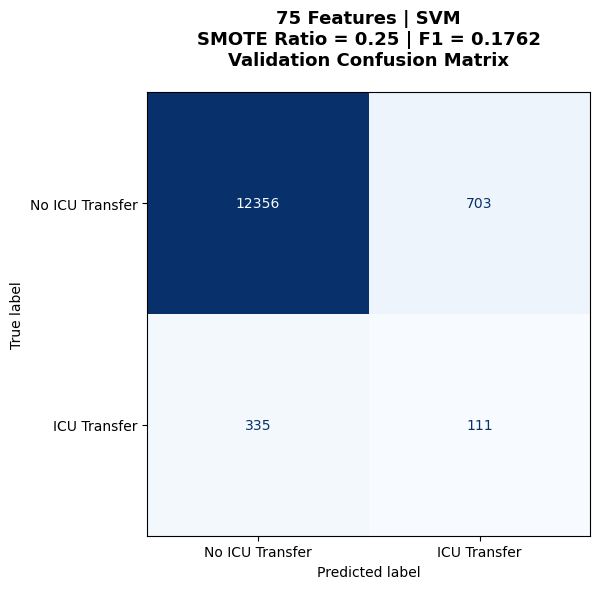

Saved: /Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/confusion_matrices/75_Features_SVM_SMOTE_025_CM.png


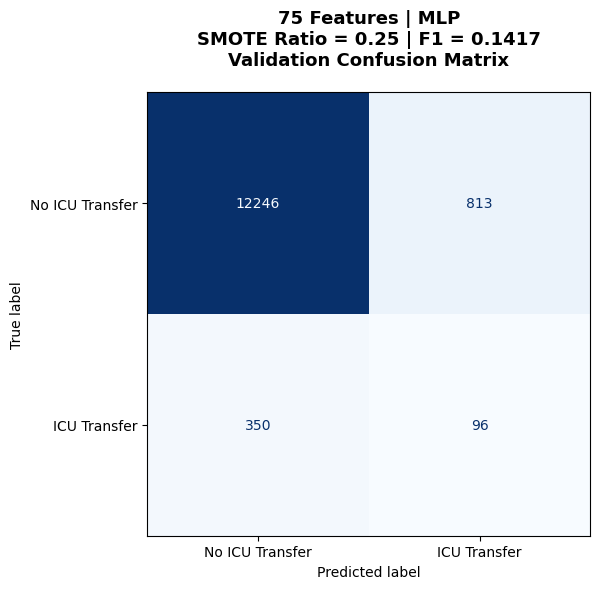

Saved: /Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/confusion_matrices/75_Features_MLP_SMOTE_025_CM.png


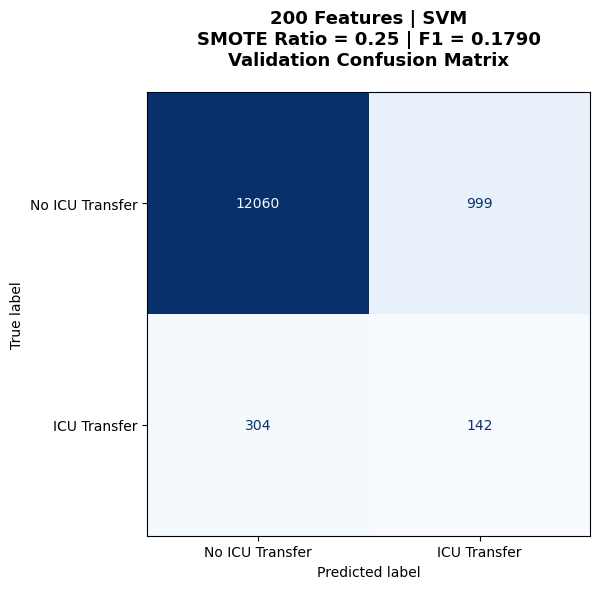

Saved: /Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/confusion_matrices/200_Features_SVM_SMOTE_025_CM.png


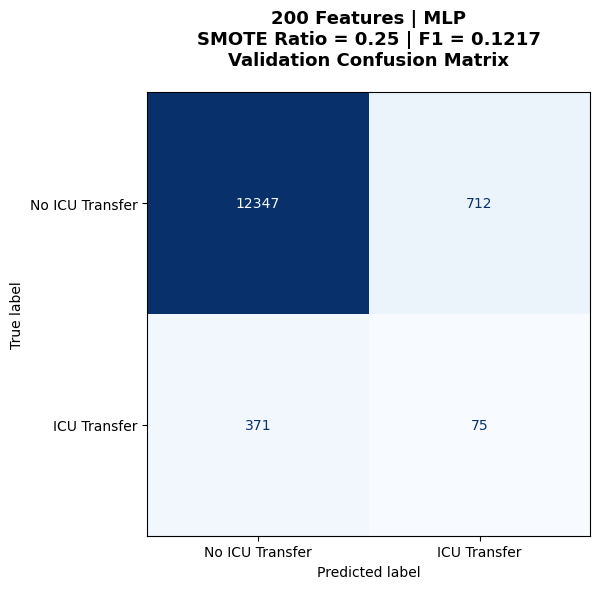

Saved: /Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/confusion_matrices/200_Features_MLP_SMOTE_025_CM.png

All four confusion matrices saved successfully.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# ============================================================
# 1. FILE PATHS — EDIT THESE
# ============================================================

RESULTS_CSV = Path(
    '/Users/amitgupta/Desktop/NUS/BN5212/Final Group Project/Post mid-term/SMOTE_Experiments/all_smote_validation_results.csv'
)

OUTPUT_DIR = Path(
    "/Users/amitgupta/Desktop/NUS/BN5212/"
    "Final Group Project/Post mid-term/"
    "SMOTE_Experiments/confusion_matrices"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD RESULTS
# ============================================================

results = pd.read_csv(RESULTS_CSV)

print("Available columns:")
print(results.columns.tolist())

# Convert SMOTE ratio to numeric
results["SMOTE_Ratio_Numeric"] = pd.to_numeric(
    results["SMOTE_Ratio"],
    errors="coerce"
)

# ============================================================
# 3. SELECT SMOTE = 0.25
# ============================================================

selected = results[
    np.isclose(
        results["SMOTE_Ratio_Numeric"],
        0.25,
        equal_nan=False
    )
    &
    results["Dataset"].isin([
        "75_Features",
        "200_Features"
    ])
    &
    results["Model"].isin([
        "SVM",
        "MLP"
    ])
].copy()

print("\nSelected experiments:")
display(
    selected[
        ["Dataset", "Model", "SMOTE_Ratio", "F1"]
    ]
)

# Verify that exactly four configurations were found
assert len(selected) == 4, (
    f"Expected 4 experiments, found {len(selected)}. "
    "Check dataset names, ratios, or duplicate rows."
)

# ============================================================
# 4. GENERATE CONFUSION MATRICES
# ============================================================

for _, row in selected.iterrows():

    dataset_name = row["Dataset"]
    model_name = row["Model"]

    tn = int(row["TN"])
    fp = int(row["FP"])
    fn = int(row["FN"])
    tp = int(row["TP"])

    # Confusion matrix layout:
    # [[TN, FP],
    #  [FN, TP]]

    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    # Verify F1 consistency
    f1_calculated = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0.0
    )

    assert np.isclose(
        f1_calculated,
        float(row["F1"]),
        atol=1e-5
    ), f"F1 mismatch for {dataset_name} - {model_name}"

    # Create plot
    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No ICU Transfer",
            "ICU Transfer"
        ]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
    f"{dataset_name.replace('_', ' ')} | {model_name}\n"
    f"SMOTE Ratio = 0.25 | F1 = {f1_calculated:.4f}\n"
    f"Validation Confusion Matrix",
    fontsize=13,
    fontweight="bold",
    pad=20
    )

    fig.tight_layout()

    # Save PNG
    filename = (
        f"{dataset_name}_{model_name}_SMOTE_025_CM.png"
    )

    save_path = OUTPUT_DIR / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")

print("\nAll four confusion matrices saved successfully.")